# Netflix Catalogue Analysis: Exploratory Data Analysis with Python

**Author:** Karan Thapa | Bachelor of Computer Science, Charles Darwin University
**Tools:** Python, pandas, matplotlib, seaborn

## 1. Project Overview

This project analyses **7,789 Netflix titles** (movies and TV shows) to understand how the catalogue is built:
what kind of content Netflix adds, where it comes from, who makes it, and how it has grown over time.

**Business questions answered**

1. How much of the catalogue is movies versus TV shows?
2. How fast did Netflix add content, and when did growth peak?
3. Which countries, genres and directors dominate the catalogue?
4. What audience ratings does Netflix target?
5. How long are typical movies and how many seasons do TV shows run?

**Dataset:** Netflix titles collected from Flixable (third party Netflix search engine), published on Kaggle.
Note: the `Release_Date` column is the date a title was **added to Netflix**, not its original release date,
so it is renamed `date_added` during cleaning.

# 2.Setup

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold", "axes.titlesize": 13})
NETFLIX_RED = "#E50914"

DATA_PATH = Path("NetflixDataAnalysis/datasets/netflix_titles.csv")   # relative path, works on any machine
IMG_DIR = Path("NetflixDataAnalysis/images")  
 # charts saved in the same folder

def save(fig, name):
    """Save a chart to the project folder so it can be reused in the README."""
    fig.savefig(IMG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

# 3.Load and Inspect the data

In [13]:
raw = pd.read_csv(DATA_PATH)
print(f"Rows: {raw.shape[0]:,} | Colums: {raw.shape[1]}")
raw.head()

Rows: 7,789 | Colums: 11


,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,"August 14, 2020",TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,"December 23, 2016",TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,"December 20, 2018",R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,"November 16, 2017",PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,"January 1, 2020",PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [14]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7789 entries, 0 to 7788
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Show_Id       7789 non-null   object
 1   Category      7789 non-null   object
 2   Title         7789 non-null   object
 3   Director      5401 non-null   object
 4   Cast          7071 non-null   object
 5   Country       7282 non-null   object
 6   Release_Date  7779 non-null   object
 7   Rating        7782 non-null   object
 8   Duration      7789 non-null   object
 9   Type          7789 non-null   object
 10  Description   7789 non-null   object
dtypes: object(11)
memory usage: 669.5+ KB


# 3.1 Data quality audit 

In [15]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str), 
    "missing": raw.isna().sum(), 
    "missing_%": (raw.isna().mean() * 100).round(2), 
    "unique": raw.nunique(),
})

print("Exact duplicate rows: ", raw.duplicated().sum())
print("Duplicated Show_Id values: ", raw['Show_Id'].duplicated().sum())
quality

Exact duplicate rows:  2
Duplicated Show_Id values:  2


,dtype,missing,missing_%,unique
Show_Id,object,0,0.00,7787
Category,object,0,0.00,2
Title,object,0,0.00,7787
Director,object,2388,30.66,4050
Cast,object,718,9.22,6831
Country,object,507,6.51,681
Release_Date,object,10,0.13,1565
Rating,object,7,0.09,14
Duration,object,0,0.00,216
Type,object,0,0.00,492


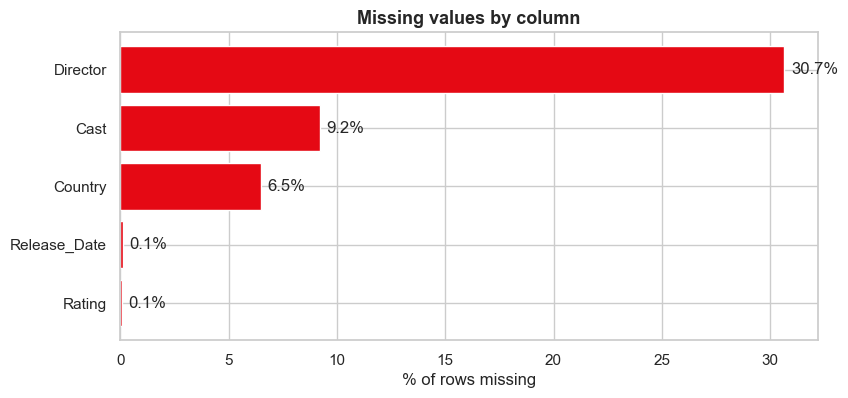

In [16]:
fig, ax = plt.subplots(figsize=(9, 4))
miss = quality["missing_%"].sort_values(ascending=True)
miss = miss[miss > 0]
ax.barh(miss.index, miss.values, color=NETFLIX_RED)
for i, v in enumerate(miss.values):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center")
ax.set(title="Missing values by column", xlabel="% of rows missing")
save(fig, "01_missing_values"); plt.show()

**Findings:** `Director` is missing for about 31% of titles (mostly TV shows, which often have no single director),
`Cast` for about 9% and `Country` for about 6.5%. `Release_Date` and `Rating` have only a handful of gaps.
There are 2 exact duplicate rows. Every column is stored as text, so dates and durations need converting before analysis.

## 4. Data Cleaning

Cleaning is done in one reusable function so the steps are clear and repeatable.

| Step | Why |
|---|---|
| Standardise column names to snake_case | Consistent, easy to type |
| Drop exact duplicate rows | Avoid double counting |
| Strip whitespace from text | Some dates have leading spaces that break parsing |
| Rename `release_date` to `date_added` and parse to datetime | Column holds the date added to Netflix |
| Fill missing `director`, `cast`, `country` with "Unknown" | Keep rows instead of dropping 30% of the data |
| Split `duration` into a number and a unit | Allows numeric analysis of movie minutes and TV seasons |
| Extract `primary_country` and `genre_list` | Many titles list several countries and genres |

In [17]:
def clean_netflix(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df.columns = df.columns.str.strip().str.lower()
    df = df.rename(columns={"release_date": "date_added", "type": "genres"})

    df = df.drop_duplicates()

    text_cols = df.select_dtypes(include=["object", "string"]).columns
    df[text_cols] = df[text_cols].apply(lambda s: s.str.strip())

    df["date_added"] = pd.to_datetime(df["date_added"], format="mixed", errors="coerce")
    df["year_added"] = df["date_added"].dt.year.astype("Int64")
    df["month_added"] = df["date_added"].dt.month_name()

    for col in ["director", "cast", "country"]:
        df[col] = df[col].fillna("Unknown")
    df["rating"] = df["rating"].fillna("Not Rated")

    dur = df["duration"].str.extract(r"(\d+)\s*(\w+)")
    df["duration_value"] = pd.to_numeric(dur[0]).astype("Int64")
    df["duration_unit"] = dur[1].str.lower().replace({"season": "seasons"})

    df["primary_country"] = df["country"].str.split(",").str[0].str.strip()
    df["genre_list"] = df["genres"].str.split(",").apply(lambda g: [x.strip() for x in g])
    return df.reset_index(drop=True)

df = clean_netflix(raw)
print(f"Rows after cleaning: {len(df):,} (removed {len(raw) - len(df)} duplicates)")
print("Unparsed dates:", df["date_added"].isna().sum())
df[["title", "category", "date_added", "year_added", "duration_value", "duration_unit", "primary_country"]].head()

Rows after cleaning: 7,787 (removed 2 duplicates)
Unparsed dates: 10


,title,category,date_added,year_added,duration_value,duration_unit,primary_country
0,3%,TV Show,2020-08-14,2020,4,seasons,Brazil
1,07:19,Movie,2016-12-23,2016,93,min,Mexico
2,23:59,Movie,2018-12-20,2018,78,min,Singapore
3,9,Movie,2017-11-16,2017,80,min,United States
4,21,Movie,2020-01-01,2020,123,min,United States


In [18]:
# Sanity checks: fail loudly if cleaning went wrong
assert df.duplicated(subset=[c for c in df.columns if c != "genre_list"]).sum() == 0
assert set(df.loc[df.category == "Movie", "duration_unit"]) == {"min"}
assert set(df.loc[df.category == "TV Show", "duration_unit"]) == {"seasons"}
print("All checks passed")

All checks passed


# 5. Exploratory Analysis

## 5.1 Movies vs TV Shows

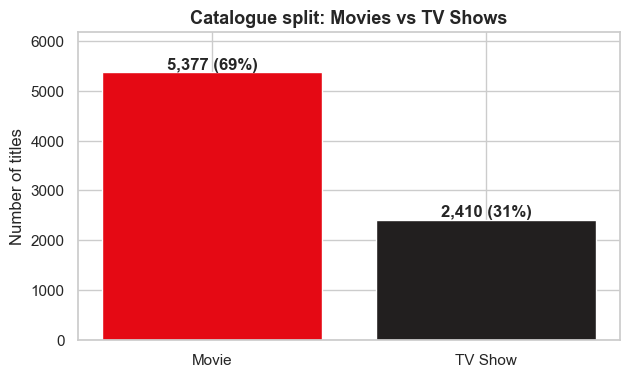

In [19]:
split = df["category"].value_counts()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(split.index, split.values, color=[NETFLIX_RED, "#221F1F"])
for i, v in enumerate(split.values):
    ax.text(i, v + 60, f"{v:,} ({v / split.sum():.0%})", ha="center", fontweight="bold")
ax.set(title="Catalogue split: Movies vs TV Shows", ylabel="Number of titles")
ax.set_ylim(0, split.max() * 1.15)
save(fig, "02_movies_vs_tv"); plt.show()

**Insight:** Movies make up about 69% of the catalogue, roughly 2.2 movies for every TV show.

# 5.2 Content growth over time

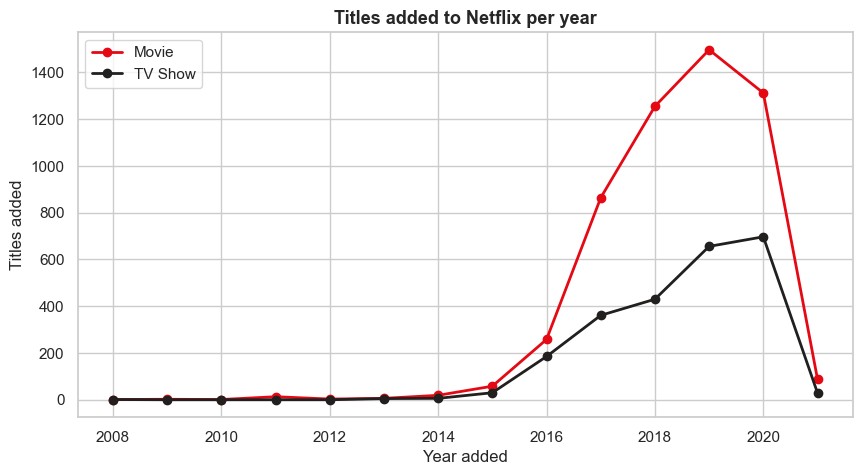

category,Movie,TV Show,total
year_added,,,
2014,19,6,25
2015,58,30,88
2016,258,185,443
2017,864,361,1225
2018,1255,430,1685
2019,1497,656,2153
2020,1312,697,2009
2021,88,29,117


In [20]:
yearly = (df.dropna(subset=["year_added"])
            .groupby(["year_added", "category"]).size()
            .unstack(fill_value=0))
fig, ax = plt.subplots()
yearly.plot(ax=ax, marker="o", color=[NETFLIX_RED, "#221F1F"], linewidth=2)
ax.set(title="Titles added to Netflix per year", xlabel="Year added", ylabel="Titles added")
ax.legend(title="")
save(fig, "03_titles_added_per_year"); plt.show()
yearly.assign(total=yearly.sum(axis=1)).tail(8)

**Insight:** Additions grew sharply from 2015 and peaked in **2019** (over 2,100 titles).
2020 stayed close to the peak. The 2021 figure is low only because the data was collected in early 2021,
so it is a partial year and should not be read as a decline.

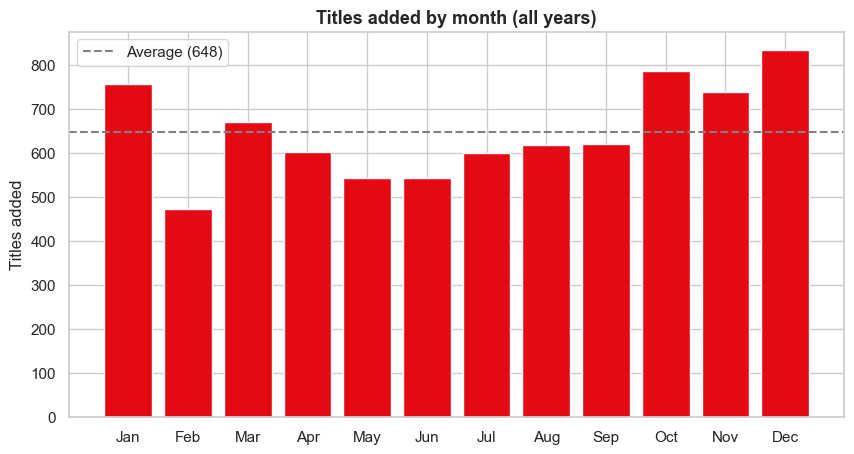

In [21]:
month_order = ["January","February","March","April","May","June","July",
               "August","September","October","November","December"]
monthly = df["month_added"].value_counts().reindex(month_order)
fig, ax = plt.subplots()
ax.bar(monthly.index.str[:3], monthly.values, color=NETFLIX_RED)
ax.axhline(monthly.mean(), ls="--", color="grey", label=f"Average ({monthly.mean():.0f})")
ax.set(title="Titles added by month (all years)", ylabel="Titles added"); ax.legend()
save(fig, "04_titles_added_by_month"); plt.show()

**Insight:** December, October and January are the busiest months for new additions, which lines up with holiday viewing periods.

# 5.3 Top countries 

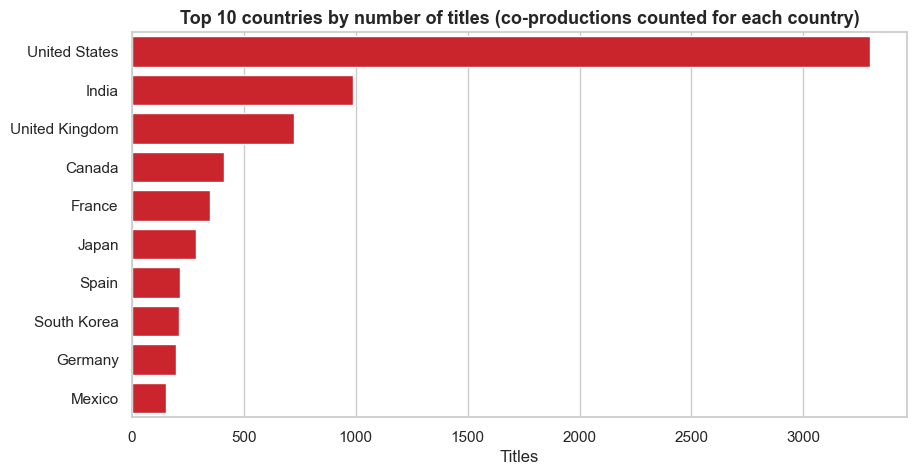

In [22]:
countries = (df.loc[df["country"] != "Unknown", "country"]
               .str.split(",").explode().str.strip())
top_countries = countries.value_counts().head(10)

fig, ax = plt.subplots()
sns.barplot(x=top_countries.values, y=top_countries.index, color=NETFLIX_RED, ax=ax)
ax.set(title="Top 10 countries by number of titles (co-productions counted for each country)",
       xlabel="Titles", ylabel="")
save(fig, "05_top_countries"); plt.show()

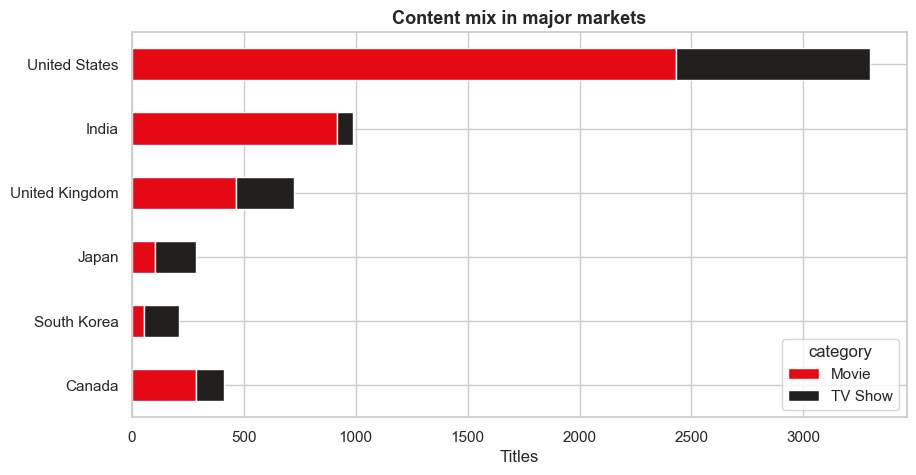

category,Movie,TV Show,tv_share
country_split,,,
United States,2431,866,0.26
India,915,75,0.08
United Kingdom,467,256,0.35
Japan,103,184,0.64
South Korea,55,157,0.74
Canada,286,126,0.31


In [23]:
# Movies vs TV shows for selected major markets
top6 = ["United States", "India", "United Kingdom", "Japan", "South Korea", "Canada"]
cc = (df.assign(country_split=df["country"].str.split(","))
        .explode("country_split"))
cc["country_split"] = cc["country_split"].str.strip()
mix = (cc[cc["country_split"].isin(top6)]
         .groupby(["country_split", "category"]).size().unstack().loc[top6])
fig, ax = plt.subplots()
mix.plot(kind="barh", stacked=True, color=[NETFLIX_RED, "#221F1F"], ax=ax)
ax.invert_yaxis(); ax.set(title="Content mix in major markets", xlabel="Titles", ylabel="")
save(fig, "06_country_content_mix"); plt.show()
mix.assign(tv_share=(mix["TV Show"] / mix.sum(axis=1)).round(2))

**Insight:** The United States dominates the catalogue. India is second and is heavily movie focused,
while Japan and South Korea lean strongly towards TV shows (anime and K-dramas), showing Netflix tailors its
international content strategy by market.

# 5.4 Top Genres

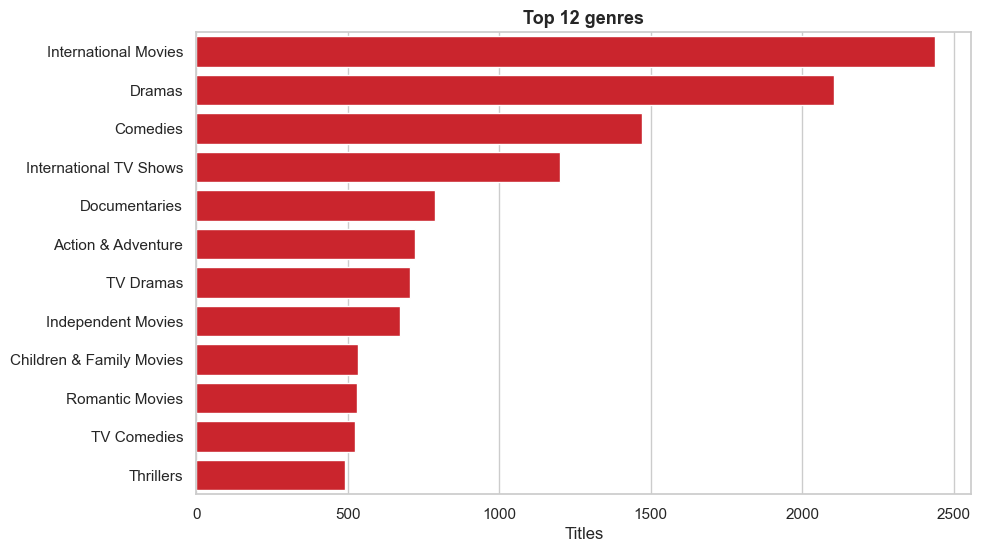

In [24]:
genres = df.explode("genre_list")
top_genres = genres["genre_list"].value_counts().head(12)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, color=NETFLIX_RED, ax=ax)
ax.set(title="Top 12 genres", xlabel="Titles", ylabel="")
save(fig, "07_top_genres"); plt.show()

**Insight:** International Movies, Dramas and Comedies lead. A title can belong to several genres, so these counts overlap.

# 5.5 Audience rating 

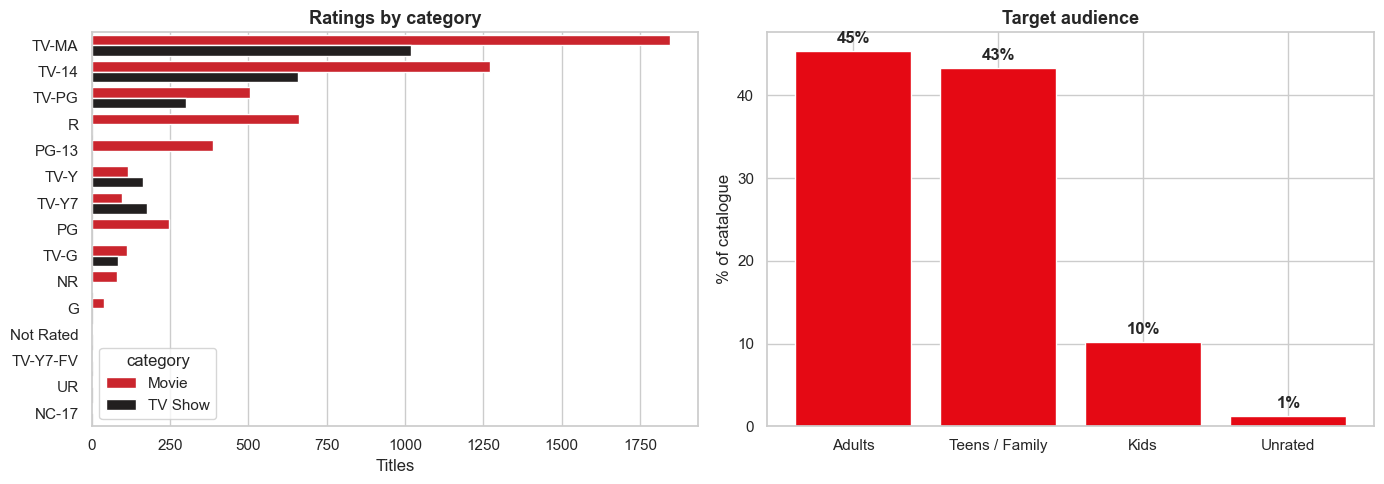

In [25]:
rating_groups = {
    "Kids": ["TV-Y", "TV-Y7", "TV-Y7-FV", "G", "TV-G"],
    "Teens / Family": ["PG", "TV-PG", "PG-13", "TV-14"],
    "Adults": ["R", "TV-MA", "NC-17"],
}
lookup = {r: g for g, rs in rating_groups.items() for r in rs}
df["audience"] = df["rating"].map(lookup).fillna("Unrated")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = df["rating"].value_counts().index
sns.countplot(data=df, y="rating", order=order, hue="category", hue_order=["Movie", "TV Show"],
              palette=[NETFLIX_RED, "#221F1F"], ax=axes[0])
axes[0].set(title="Ratings by category", xlabel="Titles", ylabel="")
aud = df["audience"].value_counts(normalize=True).mul(100)
axes[1].bar(aud.index, aud.values, color=NETFLIX_RED)
for i, v in enumerate(aud.values):
    axes[1].text(i, v + 1, f"{v:.0f}%", ha="center", fontweight="bold")
axes[1].set(title="Target audience", ylabel="% of catalogue")
plt.tight_layout(); save(fig, "08_ratings"); plt.show()

**Insight:** TV-MA (mature) is the single most common rating. Adult content (45%) narrowly leads teen and family content (43%), while kids content is only about 10% of the catalogue.

# 5.6 Duration 

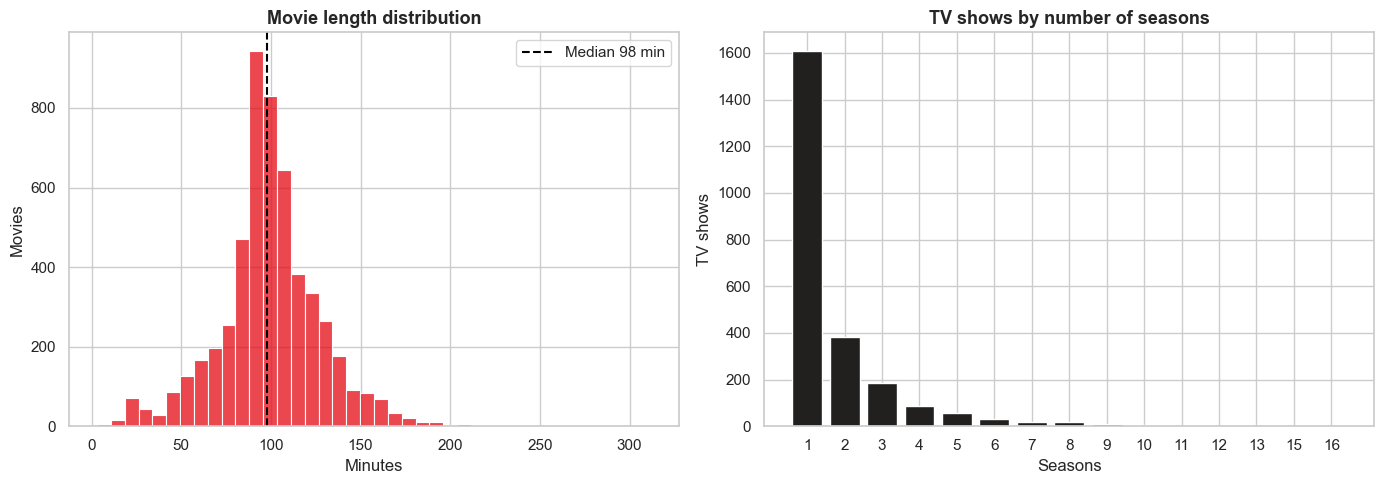

count    5377.0
mean       99.3
std        28.5
min         3.0
25%        86.0
50%        98.0
75%       114.0
max       312.0
Name: duration_value, dtype: Float64

TV shows with only 1 season: 67%


In [26]:
movies = df[df["category"] == "Movie"]
shows = df[df["category"] == "TV Show"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(movies["duration_value"].astype(float), bins=40, color=NETFLIX_RED, ax=axes[0])
med = movies["duration_value"].median()
axes[0].axvline(med, ls="--", color="black", label=f"Median {med:.0f} min")
axes[0].set(title="Movie length distribution", xlabel="Minutes", ylabel="Movies"); axes[0].legend()

seasons = shows["duration_value"].value_counts().sort_index()
axes[1].bar(seasons.index.astype(str), seasons.values, color="#221F1F")
axes[1].set(title="TV shows by number of seasons", xlabel="Seasons", ylabel="TV shows")
plt.tight_layout(); save(fig, "09_duration"); plt.show()

print(movies["duration_value"].describe().round(1))
print(f"\nTV shows with only 1 season: {(shows['duration_value'] == 1).mean():.0%}")

**Insight:** Most movies run 90 to 120 minutes (median about 98 minutes).
About two thirds of TV shows have only one season, which reflects Netflix's high volume of new and limited series.

# 5.7 Top Directors 

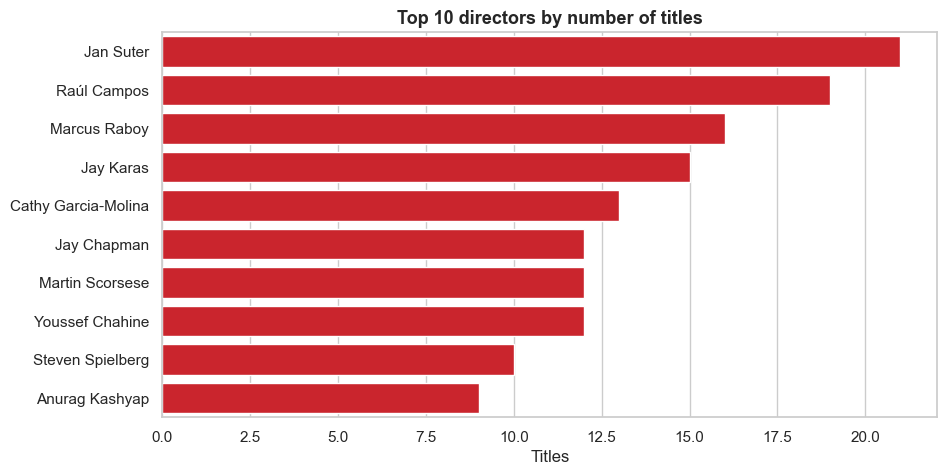

In [27]:
directors = (df.loc[df["director"] != "Unknown", "director"]
               .str.split(",").explode().str.strip())
top_dir = directors.value_counts().head(10)
fig, ax = plt.subplots()
sns.barplot(x=top_dir.values, y=top_dir.index, color=NETFLIX_RED, ax=ax)
ax.set(title="Top 10 directors by number of titles", xlabel="Titles", ylabel="")
save(fig, "10_top_directors"); plt.show()

**Note:** The original notebook counted director *strings*, so "Raúl Campos, Jan Suter" was treated as one person.
Splitting co-directors gives each person proper credit and changes the ranking.

# 6. Answering Specifice Questions 

### These reproduce the original project questions using cleaner, safer code. 

In [28]:
# Q1. Show ID and director of 'House of Cards'
df.loc[df["title"] == "House of Cards", ["show_id", "director"]]

,show_id,director
2832,s2833,"Robin Wright, David Fincher, Gerald McRaney, J..."


In [29]:
# Q2. Movies added in 2000 (none, the catalogue starts in 2008), so also show the earliest year on record
print("Movies added in 2000:", len(df[(df.category == "Movie") & (df.year_added == 2000)]))
print("Earliest year in dataset:", df["year_added"].min())

Movies added in 2000: 0
Earliest year in dataset: 2008


In [30]:
# Q3. TV shows from Australia only (single-country titles)
australia_tv = df[(df.category == "TV Show") & (df.country == "Australia")]
print(f"{len(australia_tv)} Australia TV shows")
australia_tv["title"].head(10).tolist()

46 Australia TV shows


['72 Cutest Animals',
 '72 Dangerous Animals: Asia',
 '72 Dangerous Places to Live',
 'Ask the Doctor',
 "Aunty Donna's Big Ol' House of Fun",
 'Aussie Gold Hunters',
 'Bondi Rescue',
 'Cheapest Weddings',
 'Court Justice',
 'Dance Academy']

In [31]:
# Q4. Titles featuring Tom Cruise (na=False avoids the NaN error in the original)
df.loc[df["cast"].str.contains("Tom Cruise", na=False), ["title", "category", "year_added"]]

,title,category,year_added
3860,Magnolia,Movie,2020
5071,Rain Man,Movie,2019


In [32]:
# Q5. Movies rated TV-14 from Canada, and TV shows rated R added after 2018
print("TV-14 movies from Canada:",
      len(df[(df.category == "Movie") & (df.rating == "TV-14") & (df.country == "Canada")]))
df[(df.category == "TV Show") & (df.rating == "R") & (df.year_added > 2018)][["title", "year_added"]]

TV-14 movies from Canada: 11


,title,year_added
6436,The Hateful Eight: Extended Version,2019


In [33]:
# Q6. Longest movie and longest running TV show (numeric comparison, not text)
longest_movie = movies.loc[movies["duration_value"].idxmax(), ["title", "duration"]]
longest_show = shows.loc[shows["duration_value"].idxmax(), ["title", "duration"]]
print("Longest movie:", longest_movie.to_dict())
print("Longest TV show:", longest_show.to_dict())

Longest movie: {'title': 'Black Mirror: Bandersnatch', 'duration': '312 min'}
Longest TV show: {'title': "Grey's Anatomy", 'duration': '16 Seasons'}


In [34]:
# Q7. Country with the most TV shows (counting each country in co-productions)
tv_countries = shows.loc[shows.country != "Unknown", "country"].str.split(",").explode().str.strip()
tv_countries.value_counts().head(5)

country
United States     866
United Kingdom    256
Japan             184
South Korea       157
Canada            126
Name: count, dtype: int64

## 7. Key Findings

1. **Movies dominate:** about 69% of titles are movies.
2. **Rapid growth:** additions rose sharply after 2015 and peaked in 2019 with over 2,100 titles.
3. **Global but US led:** the United States produces the most content; India is the second largest source, mainly movies, while Japan and South Korea lean towards TV.
4. **Adult focused:** TV-MA is the most common rating; adult and teen content together make up almost 90% of titles.
5. **Short commitments:** the median movie is about 98 minutes and roughly two thirds of TV shows have a single season.
6. **Holiday timing:** more titles are added in October to January than mid year.

## 8. Recommendations (if presenting to a content team)

- Keep investing in **regional TV** for Asian markets where TV already outperforms movies.
- Use the **holiday release window** for major launches, as the data shows this is already the peak for additions.
- The kids and family segment is comparatively small, which may be an **opportunity** for growth.

## 9. Limitations and Next Steps

- `Release_Date` is the date added to Netflix, not the original release date, so it reflects acquisition strategy rather than production trends.
- The data stops in early 2021, so 2021 is incomplete.
- No viewership or ratings data is available, so popularity cannot be measured.
- **Next steps:** add IMDb ratings for quality analysis, build a content based recommender using the `description` and `genres` columns with TF-IDF, and create an interactive dashboard (Streamlit or Power BI).

In [ ]:
# Export the cleaned dataset for reuse
CLEAN_PATH = DATA_PATH.parent / "netflix_cleaned.csv"
df.drop(columns=["genre_list"]).to_csv(CLEAN_PATH, index=False)
print(f"Saved {CLEAN_PATH}")

Saved NetflixDataAnalysis/datasets/netflix_cleaned.csv
